# Apprentissage de représentation : la *triplet loss*

## Partie B : un exemple jouet en 2D

Vincent Guigue (vincent.guigue@agroparistech.fr)

Dans le notebook 3_0, les représentations (embeddings) étaient apprises **indirectement**, pour prédire une note. Ici, on contraint directement la **géométrie** de l'espace de représentation : des objets similaires doivent être proches, des objets différents doivent être éloignés.

La [*triplet loss*](https://pytorch.org/docs/stable/generated/torch.nn.TripletMarginLoss.html) travaille sur des triplets (ancre $a$, positif $p$, négatif $n$) où $p$ est similaire à $a$ et $n$ ne l'est pas :
$$\mathcal L(a, p, n) = \max\big(0,\ d(a,p) - d(a,n) + \text{marge}\big)$$
Le coût est nul dès que le négatif est plus loin de l'ancre que le positif, d'au moins la marge.

**L'exercice** :
1. Générer des points 2D aléatoirement et uniformément répartis dans $[0,1]^2$, et associer une couleur aléatoire (RGB) à chaque point
2. Construire, pour chaque couleur primaire, l'ensemble des points « plutôt rouges » (resp. verts, bleus) avec un seuil
3. Construire un `Dataset` qui renvoie des triplets : 2 points de la même couleur (ancre, positif) et 1 point d'une autre couleur (négatif)
4. Considérer les **coordonnées des points comme les paramètres à apprendre** (une table d'embeddings de dimension 2), et les faire bouger avec la triplet loss
5. Visualiser le résultat : les points doivent se regrouper par couleur

## Table des matières

- [0. Configuration (device, tensorboard)](#sec-1)
- [1. Données brutes](#sec-2)
- [2. Un jeu de données de triplets](#sec-3)
- [3. La représentation à apprendre : une table d'embeddings](#sec-4)
- [4. Apprentissage](#sec-5)
- [5. Pour aller plus loin](#sec-6)

# <a id="sec-1"></a>0. Configuration (device, tensorboard)

In [99]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Sélection du device : GPU NVIDIA (cuda) > GPU Apple (mps) > CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
# NB : pour ce problème jouet (100 points en 2D), le CPU est aussi rapide

torch.manual_seed(0)
print("device :", device)

device : cuda


In [100]:
from torch.utils.tensorboard import SummaryWriter

TB_PATH = Path("/tmp/logs/module3")
TB_PATH.mkdir(parents=True, exist_ok=True)
TB_INLINE = True   # True : tensorboard affiché dans le notebook ; False : le lancer soi-même dans un terminal
print(f"Pour lancer tensorboard dans un terminal : tensorboard --logdir {TB_PATH}")
if TB_INLINE:
    %load_ext tensorboard
    %tensorboard --logdir {TB_PATH}

Pour lancer tensorboard dans un terminal : tensorboard --logdir \tmp\logs\module3
The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


ERROR: Could not find `tensorboard`. Please ensure that your PATH
contains an executable `tensorboard` program, or explicitly specify
the path to a TensorBoard binary by setting the `TENSORBOARD_BINARY`
environment variable.

# <a id="sec-2"></a>1. Données brutes

Exemple de génération et d'affichage de points colorés avec `numpy` et `matplotlib` :

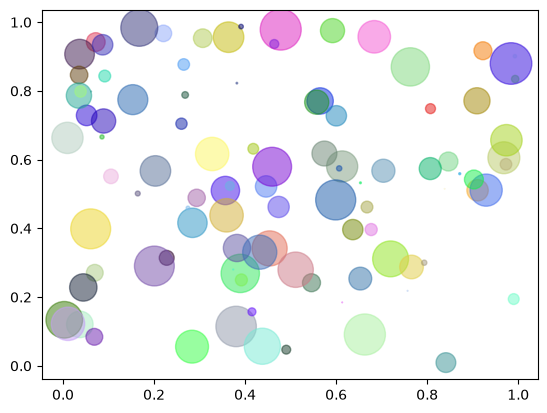

In [101]:
N = 100
x = np.random.rand(N)
y = np.random.rand(N)
colors = np.random.rand(N, 3)          # tirage aléatoire RGB
area = (30 * np.random.rand(N))**2      # rayons de 0 à 15 points

plt.scatter(x, y, s=area, c=colors, alpha=0.5)
plt.show()

Le même jeu en pytorch : `X` contient les coordonnées `(N, 2)` et `C` les couleurs `(N, 3)`.

Avec `facile = True`, chaque point reçoit une couleur pure (sa composante dominante) : les groupes sont alors disjoints. Commencer ainsi, puis tester `facile = False` (cf. dernière partie).

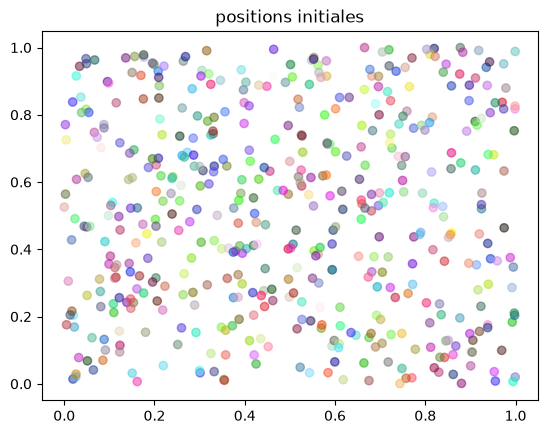

In [102]:
N = 500
X = torch.rand(N, 2)        # positions initiales
C = torch.rand(N, 3)        # couleurs RGB

facile = False
if facile:
    # données plus faciles : soit rouge, soit vert, soit bleu (one-hot de la composante dominante)
    C = F.one_hot(C.argmax(1), 3).float()

plt.scatter(X[:, 0], X[:, 1], c=C.numpy(), alpha=0.5)
plt.title("positions initiales");

# <a id="sec-3"></a>2. Un jeu de données de triplets

On construit un `Dataset` qui renvoie des triplets d'**indices** de points `(ancre, positif, négatif)` :
- on tire une couleur $c$ au hasard (rouge, vert ou bleu),
- l'ancre est un point du groupe $c$ (on utilise l'indice `i` pour parcourir le groupe), le positif un point du groupe $c$ tiré au hasard,
- le négatif est un point tiré au hasard **hors** du groupe $c$.

Les groupes (`self.groups[c]`) et leurs complémentaires (`self.others[c]`) sont calculés dans le constructeur (un point est « plutôt de couleur $c$ » si sa composante $c$ dépasse `1 - thres`).

**TODO :** compléter la méthode `__getitem__`. Pour tirer un élément au hasard dans un tenseur d'indices `t` : `t[torch.randint(len(t), (1,))].squeeze()`.

*Pourquoi des indices et pas directement les coordonnées ?* Parce que les coordonnées vont être des **paramètres appris** (section 3) : le jeu de données ne fait que dire *quels* points comparer.

In [103]:
class ColorsDataset(Dataset):
    """Renvoie des triplets d'indices de points (ancre, positif, négatif)"""
    def __init__(self, colors, thres=0.4):
        self.n = len(colors)
        # pour chaque couleur c : indices des points « plutôt c », et des autres
        self.groups = [(colors[:, c] > 1 - thres).nonzero().squeeze(1) for c in range(3)]
        self.others = [(colors[:, c] <= 1 - thres).nonzero().squeeze(1) for c in range(3)]

    def __len__(self):
        return self.n    # une époque = N triplets

    def __getitem__(self, i):
        c=C[i].argmax().item()
        pos = np.random.choice(self.groups[c])
        neg = np.random.choice(self.others[c])
        return torch.tensor(i), torch.tensor(pos), torch.tensor(neg)


In [104]:
# Vérification
# 1. construction de l'objet
data = ColorsDataset(C)
print("taille des groupes :", [len(g) for g in data.groups])

# 2. tirage d'un triplet
ia, ip, ineg = data[0]
print(ia, ip, ineg)
print("couleurs :", C[ia], C[ip], C[ineg])

# 3. sur 1000 tirages, l'ancre et le positif ont toujours la même couleur, le négatif jamais (cas facile)
ok = all(C[a].argmax() == C[p].argmax() != C[n].argmax() for a, p, n in (data[k % N] for k in range(1000)))
print("triplets cohérents :", ok)

taille des groupes : [194, 189, 200]
tensor(0) tensor(14) tensor(268)
couleurs : tensor([0.4575, 0.1101, 0.4969]) tensor([0.3711, 0.2136, 0.7402]) tensor([0.1324, 0.7426, 0.2021])
triplets cohérents : False


# <a id="sec-4"></a>3. La représentation à apprendre : une table d'embeddings

Les positions des points sont les **paramètres** du modèle : on les stocke dans un `nn.Embedding(N, 2)` (cf. notebook 3_0), initialisé avec les positions aléatoires `X`. `emb(indices)` renvoie les positions des points demandés, et l'optimiseur pourra les modifier comme n'importe quel poids d'un réseau.

**Illustration.** Calcul de la triplet loss sur un seul triplet et affichage de $-\nabla$ (la direction dans laquelle la descente de gradient va déplacer les points) : l'ancre (A) est attirée vers le positif (P) et repoussée du négatif (N).

loss : 1.311249017715454


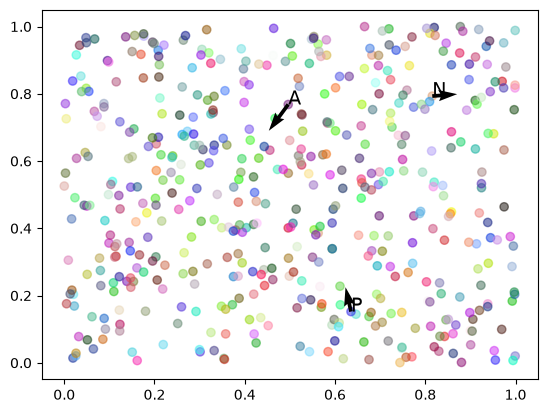

In [105]:
def plot_points(P, C, G=None, ax=None, title=""):
    """P : positions (N, 2), C : couleurs (N, 3), G : gradients (N, 2) optionnels (flèches = -G)"""
    ax = ax or plt.gca()
    ax.scatter(P[:, 0], P[:, 1], c=C, alpha=0.5)
    if G is not None:
        moved = (G**2).sum(1) > 1e-8
        ax.quiver(P[moved, 0], P[moved, 1], -G[moved, 0], -G[moved, 1])
    ax.set_title(title)

emb = nn.Embedding(N, 2)
with torch.no_grad():
    emb.weight.copy_(X)

ia, ip, ineg = data[0]
emb.zero_grad()
loss = nn.TripletMarginLoss()(emb(ia).unsqueeze(0), emb(ip).unsqueeze(0), emb(ineg).unsqueeze(0))
loss.backward()
print("loss :", loss.item())

P, G = emb.weight.detach().numpy(), emb.weight.grad.numpy()
plot_points(P, C.numpy(), G)
for k, lab in zip([ia, ip, ineg], "APN"):
    plt.text(P[k, 0], P[k, 1], lab, fontsize=14)

**Question.** Avec les valeurs par défaut (`margin=1`, distance euclidienne), quand la loss d'un triplet est-elle nulle ? Est-ce possible au début de l'apprentissage, quand les points sont dans $[0,1]^2$ ?

Triplet loss:
$$\mathcal L(a, p, n) = \max\big(0,\ d(a,p) - d(a,n) + \text{marge}\big)$$

Donc la loss est nulle si $$\mathcal \ d(a,p) - d(a,n) + \text{marge} < 0$$

Donc avec margin = 1, il faut $$\mathcal \ d(a,p) <  d(a,n)- 1$$

Ce qui est possible avec a et p collés ($ \mathcal \ d(a,p) = 0$ ) et n dans le coin opposé ($ \mathcal \ d(a,p) = 1.4$)

# <a id="sec-5"></a>4. Apprentissage

Écrire la boucle d'apprentissage : pour chaque batch de triplets `(ia, ip, ineg)` fourni par le `DataLoader` :
1. récupérer les positions des points avec `emb`,
2. calculer la triplet loss,
3. rétro-propager, mettre à jour les positions (`optimizer.step()`), remettre les gradients à zéro.

Enregistrer la loss moyenne de chaque époque dans tensorboard et l'afficher toutes les 20 époques.

In [111]:
# Paramétrage
dload = DataLoader(data, batch_size=16, shuffle=True)
nb_epochs = 50000
lr = 0.3
loss_fn = nn.TripletMarginLoss(margin=2)
loss_fn.to(device)
emb = nn.Embedding(N, 2)
with torch.no_grad():
    emb.weight.copy_(X)     # on repart des positions initiales
emb = emb.to(device)

optimizer = torch.optim.SGD(emb.parameters(), lr=lr)
writer = SummaryWriter(TB_PATH / f"triplet-toy-{time.strftime('%H%M%S')}")

for epoch in range(nb_epochs):
    ia, ip, ineg = next(iter(dload))
    ia = ia.to(device)
    ip = ip.to(device)
    ineg = ineg.to(device)
    emb.zero_grad()
    loss = loss_fn(emb(ia).unsqueeze(0), emb(ip).unsqueeze(0), emb(ineg).unsqueeze(0))
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    writer.add_scalar("loss/train", loss, epoch)
    if epoch %1000 ==0:
        print(f"loss = {loss:.3f}     |   epoch = {epoch} / {nb_epochs}")
writer.close()

loss = 2.042     |   epoch = 0 / 50000
loss = 1.680     |   epoch = 1000 / 50000
loss = 1.466     |   epoch = 2000 / 50000
loss = 1.429     |   epoch = 3000 / 50000
loss = 0.697     |   epoch = 4000 / 50000
loss = 1.180     |   epoch = 5000 / 50000
loss = 0.906     |   epoch = 6000 / 50000
loss = 0.296     |   epoch = 7000 / 50000
loss = 0.494     |   epoch = 8000 / 50000
loss = 0.224     |   epoch = 9000 / 50000
loss = 0.970     |   epoch = 10000 / 50000
loss = 0.945     |   epoch = 11000 / 50000
loss = 0.606     |   epoch = 12000 / 50000
loss = 0.692     |   epoch = 13000 / 50000
loss = 0.709     |   epoch = 14000 / 50000
loss = 0.766     |   epoch = 15000 / 50000
loss = 0.775     |   epoch = 16000 / 50000
loss = 0.344     |   epoch = 17000 / 50000
loss = 0.431     |   epoch = 18000 / 50000
loss = 0.360     |   epoch = 19000 / 50000
loss = 0.529     |   epoch = 20000 / 50000
loss = 0.639     |   epoch = 21000 / 50000
loss = 0.259     |   epoch = 22000 / 50000
loss = 0.735     |   epo

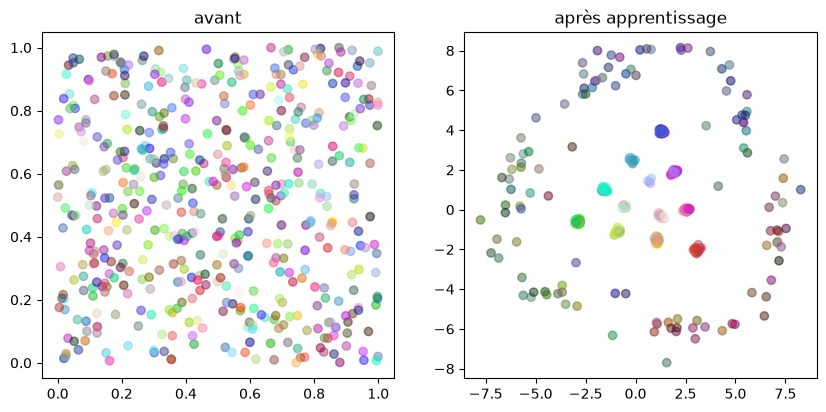

In [114]:
# vérification graphique
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
plot_points(X.numpy(), C.numpy(), ax=axes[0], title="avant")
plot_points(emb.weight.detach().cpu().numpy(), C.numpy(), ax=axes[1], title="après apprentissage")

# <a id="sec-6"></a>5. Pour aller plus loin

1. Relancer avec `facile = False` : les couleurs sont mélangées, un point peut appartenir à plusieurs groupes (ou à aucun). Que devient la représentation ?
2. Faire varier la marge (`nn.TripletMarginLoss(margin=...)`) : quel effet sur la distance entre les groupes ?
3. Que se passerait-il sans négatif (en minimisant seulement $d(a,p)$) ?

In [108]:
##  TODO 